## Download Pi3

In [1]:
%cd /content

!rm -rf /content/Pi3
!git clone https://github.com/yyfz/Pi3.git

%cd /content/Pi3

!pip install -q --upgrade pip
!pip uninstall -y numpy scipy scikit-image opencv-python opencv-python-headless opencv-contrib-python rasterio pandas
!pip install -q "numpy==1.26.4"
!pip install -q -r requirements.txt
!pip install -q -e .

/content
Cloning into 'Pi3'...
remote: Enumerating objects: 504, done.
remote: Counting objects: 100% (191/191), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 504 (delta 123), reused 77 (delta 75), pack-reused 313 (from 1)
Receiving objects: 100% (504/504), 42.94 MiB | 10.30 MiB/s, done.
Resolving deltas: 100% (169/169), done.
/content/Pi3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 83.5 MB/s eta 0:00:00
Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
Found existing installation: scipy 1.16.3
Uninstalling scipy-1.16.3:
  Successfully uninstalled scipy-1.16.3
Found existing installation: scikit-image 0.25.2
Uninstalling scikit-image-0.25.2:
  Successfully uninstalled scikit-image-0.25.2
Found existing installation: opencv-python 4.11.0.86
Uninstalling opencv-python-4.11.0.86:
  Successfully uninstalled opencv-python-4.11.0.86
Found existing installation: opencv-python-headless 4.13.0.92
Unin

In [1]:
import numpy as np
import torch

print("numpy:", np.__version__)
print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available())

%cd /content/Pi3

from pi3.models.pi3x import Pi3X
from pi3.utils.basic import load_images_as_tensor

print("Pi3 imports OK")

numpy: 1.26.4
torch: 2.5.1+cu124
cuda: True
/content/Pi3
Warning, cannot find cuda-compiled version of RoPE2D, using a slow pytorch version instead
Pi3 imports OK


## Download Image

In [2]:
# Step 1: set Mapillary image ID and access token
IMAGE_ID = "842149990032290"

# Paste your Mapillary access token here
MAPILLARY_TOKEN = "<YOUR_MAPILLARY_TOKEN>"

Status: 200
{"id":"842149990032290","captured_at":1440247237865,"compass_angle":84.749017202418,"geometry":{"type":"Point","coordinates":[-89.214663333333,42.28008]},"height":1920,"width":2560,"thumb_1024_url":"https:\/\/scontent-sin2-2.xx.fbcdn.net\/m1\/v\/t6\/An8akNT_-q7w0WCUDZgUVwhueZ0UkCIZ65qlosYJBt0pIfjyNZf46W0PvzCSX5x1GowfFJLHyTGHQaQQVrDtHyycwW4DtDQcncYB-pe2LZlz4k77FnwzvymKv8em0yX8lbxtAmT2yjDoyF6Ic9CzCA?stp=s1024x768&edm=ALXxkZ8EAAAA&_nc_gid=V0fGKNheNbT7Nk2uIX_Mpg&_nc_oc=Adqz2cU5wH29ZNQBJDWth5FYUwYEyq
Image metadata:
id : 842149990032290
captured_at : 1440247237865
compass_angle : 84.749017202418
geometry : {'type': 'Point', 'coordinates': [-89.214663333333, 42.28008]}
height : 1920
width : 2560
Download URL exists: True
Saved to: /content/selected_images/mapillary_842149990032290.jpg
Image size: (2560, 1920)
Image shape: (1920, 2560, 3)


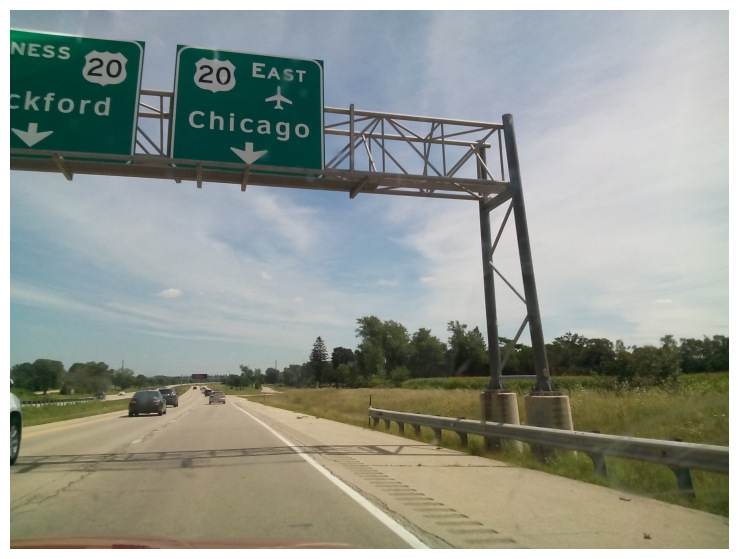

In [3]:
import os
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np



SAVE_DIR = "/content/selected_images"
os.makedirs(SAVE_DIR, exist_ok=True)

fields = ",".join([
    "id",
    "captured_at",
    "compass_angle",
    "geometry",
    "height",
    "width",
    "thumb_1024_url",
    "thumb_2048_url",
    "thumb_original_url",
])

url = f"https://graph.mapillary.com/{IMAGE_ID}"
params = {
    "access_token": MAPILLARY_TOKEN,
    "fields": fields,
}

r = requests.get(url, params=params)
print("Status:", r.status_code)
print(r.text[:500])
r.raise_for_status()

meta = r.json()
img_url = meta.get("thumb_original_url") or meta.get("thumb_2048_url") or meta.get("thumb_1024_url")

print("Image metadata:")
for k, v in meta.items():
    if "url" not in k:
        print(k, ":", v)

print("Download URL exists:", img_url is not None)

img_response = requests.get(img_url)
img_response.raise_for_status()

img = Image.open(BytesIO(img_response.content)).convert("RGB")

save_path = os.path.join(SAVE_DIR, f"mapillary_{IMAGE_ID}.jpg")
img.save(save_path, quality=95)

img_np = np.array(img)

print("Saved to:", save_path)
print("Image size:", img.size)
print("Image shape:", img_np.shape)

plt.figure(figsize=(10, 7))
plt.imshow(img_np)
plt.axis("off")
plt.show()

IMAGE_PATH: /content/selected_images/mapillary_842149990032290.jpg
Image shape: (1920, 2560, 3)
p1: (900, 560)
p2: (900, 1600)


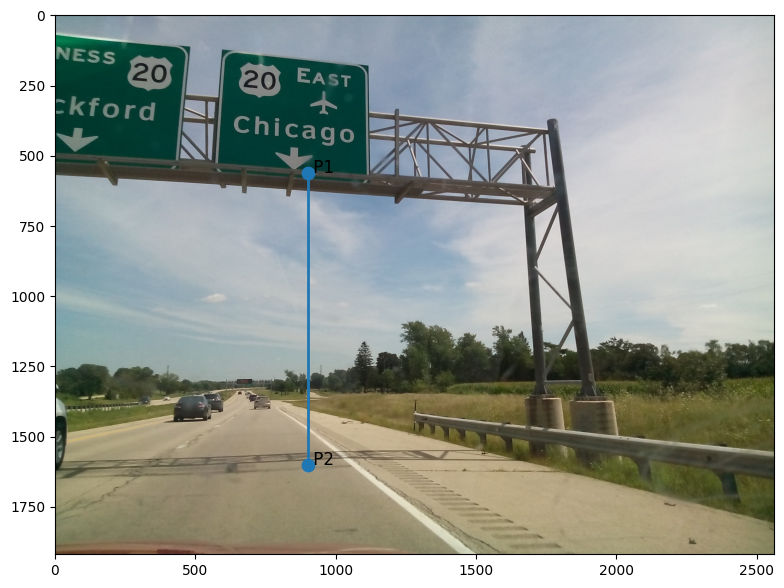

In [4]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = save_path

img = Image.open(IMAGE_PATH).convert("RGB")
img_np = np.array(img)

p1 = (900, 560)
p2 = (900, 1600)

print("IMAGE_PATH:", IMAGE_PATH)
print("Image shape:", img_np.shape)
print("p1:", p1)
print("p2:", p2)

plt.figure(figsize=(10, 7))
plt.imshow(img_np)
plt.scatter([p1[0], p2[0]], [p1[1], p2[1]], s=80)
plt.plot([p1[0], p2[0]], [p1[1], p2[1]], linewidth=2)
plt.text(p1[0], p1[1], " P1", fontsize=12)
plt.text(p2[0], p2[1], " P2", fontsize=12)
plt.axis("on")
plt.show()

In [5]:
import os
import torch
import numpy as np
from PIL import Image

%cd /content/Pi3

PI3_IMAGE_DIR = "/content/pi3_single_image"
os.makedirs(PI3_IMAGE_DIR, exist_ok=True)

for f in os.listdir(PI3_IMAGE_DIR):
    os.remove(os.path.join(PI3_IMAGE_DIR, f))

img = Image.open(IMAGE_PATH).convert("RGB")
img.save(os.path.join(PI3_IMAGE_DIR, "000.png"))

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

from pi3.models.pi3x import Pi3X
from pi3.utils.basic import load_images_as_tensor

model_pi3 = Pi3X.from_pretrained("yyfz233/Pi3X").to(device).eval()

imgs = load_images_as_tensor(PI3_IMAGE_DIR, interval=1).to(device)
print("Pi3 input shape:", imgs.shape)

if device == "cuda":
    major, minor = torch.cuda.get_device_capability()
    dtype = torch.bfloat16 if major >= 8 else torch.float16

    with torch.no_grad():
        with torch.amp.autocast("cuda", dtype=dtype):
            results_pi3 = model_pi3(imgs[None])
else:
    with torch.no_grad():
        results_pi3 = model_pi3(imgs[None])

print("Pi3X result keys:", results_pi3.keys())

/content/Pi3
Device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/5.44G [00:00<?, ?B/s]

Loading images from directory: /content/pi3_single_image
Found 1 images/frames. Processing...
All images will be resized to a uniform size: (574, 434)
Pi3 input shape: torch.Size([1, 3, 434, 574])
Pi3X result keys: dict_keys(['points', 'local_points', 'rays', 'conf', 'camera_poses', 'metric'])


In [6]:
pi3_points = results_pi3["points"][0, 0].detach().float().cpu().numpy()

if "conf" in results_pi3:
    pi3_conf = torch.sigmoid(results_pi3["conf"][0, 0, ..., 0]).detach().float().cpu().numpy()
    pi3_mask = pi3_conf > 0.5
else:
    pi3_conf = None
    pi3_mask = np.isfinite(pi3_points).all(axis=-1)

pi3_mask = pi3_mask & np.isfinite(pi3_points).all(axis=-1)

print("Pi3 points shape:", pi3_points.shape)
print("Pi3 valid ratio:", pi3_mask.mean())

Pi3 points shape: (434, 574, 3)
Pi3 valid ratio: 0.0


## Pi3 Inference

conf min: 4.032243396068225e-06
conf max: 0.4231492578983307
conf mean: 0.1175328940153122
conf p10/p50/p90: [1.71606052e-05 2.67775990e-02 3.59032825e-01]
Pi3 points shape: (434, 574, 3)
Finite ratio: 1.0
Valid ratio after threshold: 0.4652812344449975
Pi3X
p1 original: (900, 560) -> pi3: (202, 127) -> valid: (202, 127) shift: 0
p2 original: (900, 1600) -> pi3: (202, 362) -> valid: (202, 362) shift: 0
Pi3X distance: 3.460 approximate m
P1 3D: [-1.9086552  0.7380861 -2.043071 ]
P2 3D: [-0.11555418  2.6311667   0.23191354]


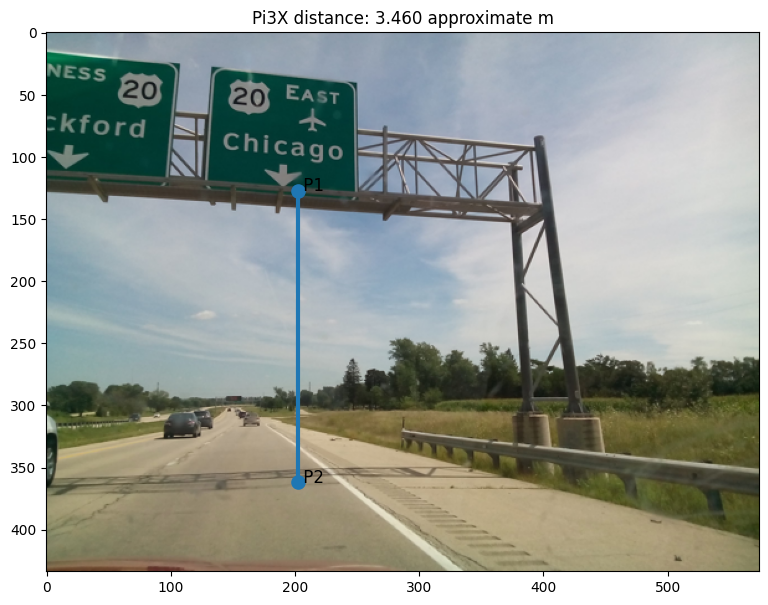

In [9]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

# Extract Pi3 points
pi3_points = results_pi3["points"][0, 0].detach().float().cpu().numpy()

# Build a less strict valid mask
finite_mask = np.isfinite(pi3_points).all(axis=-1)

if "conf" in results_pi3:
    pi3_conf = torch.sigmoid(results_pi3["conf"][0, 0, ..., 0]).detach().float().cpu().numpy()

    print("conf min:", float(np.nanmin(pi3_conf)))
    print("conf max:", float(np.nanmax(pi3_conf)))
    print("conf mean:", float(np.nanmean(pi3_conf)))
    print("conf p10/p50/p90:", np.percentile(pi3_conf[np.isfinite(pi3_conf)], [10, 50, 90]))

    # Less strict than 0.5
    pi3_mask = (pi3_conf > 0.05) & finite_mask
else:
    pi3_conf = None
    pi3_mask = finite_mask

print("Pi3 points shape:", pi3_points.shape)
print("Finite ratio:", finite_mask.mean())
print("Valid ratio after threshold:", pi3_mask.mean())

# If confidence threshold is still too strict, fallback to finite-only
if pi3_mask.mean() < 0.01:
    print("Valid mask too sparse. Falling back to finite-only mask.")
    pi3_mask = finite_mask

p1 = (900, 560)
p2 = (900, 1600)

def scale_point(p_xy, from_hw, to_hw):
    x, y = p_xy
    H_from, W_from = from_hw
    H_to, W_to = to_hw

    x2 = int(round(x * W_to / W_from))
    y2 = int(round(y * H_to / H_from))

    x2 = max(0, min(W_to - 1, x2))
    y2 = max(0, min(H_to - 1, y2))

    return (x2, y2)


def snap_to_nearest_valid(p_xy, valid_mask, max_radius=300):
    x, y = map(int, p_xy)
    H, W = valid_mask.shape

    if 0 <= x < W and 0 <= y < H and valid_mask[y, x]:
        return (x, y), 0

    for r in range(1, max_radius + 1):
        x0, x1 = max(0, x - r), min(W, x + r + 1)
        y0, y1 = max(0, y - r), min(H, y + r + 1)

        patch = valid_mask[y0:y1, x0:x1]
        ys, xs = np.where(patch)

        if len(xs) > 0:
            xs_global = xs + x0
            ys_global = ys + y0
            d2 = (xs_global - x) ** 2 + (ys_global - y) ** 2
            idx = np.argmin(d2)
            return (int(xs_global[idx]), int(ys_global[idx])), int(round(np.sqrt(d2[idx])))

    raise ValueError(f"No valid pixel found within radius {max_radius}.")


def measure_3d_distance(points, valid_mask, p1_xy, p2_xy):
    x1, y1 = p1_xy
    x2, y2 = p2_xy

    if not valid_mask[y1, x1]:
        raise ValueError("P1 is invalid.")
    if not valid_mask[y2, x2]:
        raise ValueError("P2 is invalid.")

    P1 = points[y1, x1]
    P2 = points[y2, x2]

    dist = float(np.linalg.norm(P1 - P2))
    return dist, P1, P2


H_img, W_img = img_np.shape[:2]
H_pi3, W_pi3 = pi3_points.shape[:2]

p1_pi3 = scale_point(p1, (H_img, W_img), (H_pi3, W_pi3))
p2_pi3 = scale_point(p2, (H_img, W_img), (H_pi3, W_pi3))

p1_pi3_safe, s1_pi3 = snap_to_nearest_valid(p1_pi3, pi3_mask, max_radius=300)
p2_pi3_safe, s2_pi3 = snap_to_nearest_valid(p2_pi3, pi3_mask, max_radius=300)

dist_pi3, P1_pi3, P2_pi3 = measure_3d_distance(
    pi3_points,
    pi3_mask,
    p1_pi3_safe,
    p2_pi3_safe
)

print("Pi3X")
print("p1 original:", p1, "-> pi3:", p1_pi3, "-> valid:", p1_pi3_safe, "shift:", s1_pi3)
print("p2 original:", p2, "-> pi3:", p2_pi3, "-> valid:", p2_pi3_safe, "shift:", s2_pi3)
print(f"Pi3X distance: {dist_pi3:.3f} approximate m")
print("P1 3D:", P1_pi3)
print("P2 3D:", P2_pi3)

# Plot
pi3_vis = np.array(Image.fromarray(img_np).resize((W_pi3, H_pi3)))

plt.figure(figsize=(10, 7))
plt.imshow(pi3_vis)

plt.scatter(
    [p1_pi3_safe[0], p2_pi3_safe[0]],
    [p1_pi3_safe[1], p2_pi3_safe[1]],
    s=90
)

plt.plot(
    [p1_pi3_safe[0], p2_pi3_safe[0]],
    [p1_pi3_safe[1], p2_pi3_safe[1]],
    linewidth=3
)

plt.text(p1_pi3_safe[0], p1_pi3_safe[1], " P1", fontsize=12)
plt.text(p2_pi3_safe[0], p2_pi3_safe[1], " P2", fontsize=12)

plt.title(f"Pi3X distance: {dist_pi3:.3f} approximate m")
plt.axis("on")
plt.show()